# Pilot Study: Sizing the Noise-Level Sweep (Study 1)

Extends the 6-method comparison pilot (`pilot_power_analysis.ipynb`) with a second
crossed factor: SNR level. Same design logic -- one simulated ground truth per
`(region, repetition, snr)` reconstructed by all 6 methods, with a mixed-effects model
per `(outcome, snr)` to extract variance components, then Monte Carlo power/precision
curves across a `(k regions, r repetitions)` grid -- fit **separately per SNR level**
rather than as one joint `method x snr x region` model: a full random-slope covariance
was already singular at the original pilot's scale (208 rows, 26 groups), and adding a
noise dimension only makes that worse, so this keeps the same well-identified
`re_formula="~1"` + named `vc_formula` form the original pilot validated, just refit once
per SNR value.

**SNR levels**: `[20, 10, 5, 2, 1]` -- the existing noise-sweep convention from
`simulation_spike.ipynb`'s "Noise/SNR sweep dataset" (`[50, 20, 10, 5, 2, 1, None]`),
minus `50` (the original 6-method pilot found the method main effect already saturated
near 1.0 across the board -- the easiest condition is the least informative for
detecting method differences) and minus the noise-only `None` condition (degenerate
AP/localization-error, same reasoning as `inverse-noisesweep.ipynb`).

**Regions**: the same 26 regions as the original pilot (`pilot_region_selection.tsv`) --
stratification is about spatial coverage, unrelated to noise level, so there's no reason
to reselect it.

**Recommendation logic**: since the real study presents every noise level together, the
final `(k, r)` is sized to the *worst* `(outcome, snr)` combination across the whole
grid -- the same "size to the hardest case" principle the original pilot used across
outcomes alone.

**Companion scripts** (only the two expensive data-generation steps -- everything else
runs here, same convention as `pilot_power_analysis.ipynb`):
- `pilot_noise_01_generate.py` -- simulates 26 regions x 5 SNR levels x 4 repetitions
  (~520 runs)
- `pilot_noise_02_solve.py` -- solves all 6 methods on each run, checkpointed, tagged
  with `snr`

## 🧬 - Running the pilot (run separately first)

`pilot_noise_01_generate.py` simulates the 26 pilot regions x 5 SNR levels x 4
repetitions (fresh stochastic noise draw each time) -- same head model / epoch /
propagation config as `simulation_spike.ipynb` and the original pilot.

`pilot_noise_02_solve.py` then solves all 6 methods on each of the ~520 runs, same
hrp/pp/curve scoring as the original pilot (`build_phase_data_hrp_pp_curve` /
`score_source_reconstruction`), with each checkpoint row additionally tagged `snr`.
Checkpointed per run (`pilot_noise_metrics/run-{run:03d}.json` + `_curves.npz`), same
crash-recovery behavior as the original pilot.

Run both before executing the cells below.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

import mindmap as mm

dm = mm.io.TutoManager("../../config.yml")
sub_pilot = "simf10-pilot-noise"

METRICS_DIR = Path("pilot_noise_metrics")
OUTCOMES = ["localization_error_hrp", "ap_hrp", "ap_pp", "correlation_auc"]
METHODS = ["wcset", "cset", "mce", "sloreta", "dspm", "mne"]
SNR_LEVELS = [20, 10, 5, 2, 1]
M = len(METHODS)

## 📊 - Aggregate outcome measures

Same three outcome measures per `(region, repetition, snr, method)` as the original
pilot. `snr` is already a column in each checkpoint row (tagged by
`pilot_noise_02_solve.py`), so `load_pilot_checkpoints` only needs to pull
`region`/`repetition` from the run index -- `snr` comes along for free.

In [2]:
df_index = pd.read_csv(dm.roots["sim"] / f"sub-{sub_pilot}" / "simulation_index.tsv", sep="\t")

df = mm.analysis.power.load_pilot_checkpoints(df_index, METRICS_DIR, index_cols=("region", "repetition"))
print(f"Aggregated {len(df)} (region,repetition,snr,method) rows "
      f"({df['run'].nunique()} runs x {df['method'].nunique()} methods x {df['snr'].nunique()} SNR levels).")
df.to_csv("pilot_noise_outcomes.tsv", sep="\t", index=False)
df.head()

Aggregated 3120 (region,repetition,snr,method) rows (520 runs x 6 methods x 5 SNR levels).


,run,method,snr,localization_error_hrp,ap_hrp,ap_pp,correlation_auc,region,repetition
0,1,wcset,20.0,0.000000,0.615645,0.937838,0.400712,ctx-rh-posteriorcingulate_2,1
1,1,cset,20.0,0.000000,0.690641,0.907440,0.415688,ctx-rh-posteriorcingulate_2,1
2,1,mce,20.0,0.000000,0.418165,0.839060,0.197961,ctx-rh-posteriorcingulate_2,1
3,1,sloreta,20.0,0.000000,0.525033,0.870663,0.187043,ctx-rh-posteriorcingulate_2,1
4,1,dspm,20.0,2.045232,0.511843,0.867667,0.201226,ctx-rh-posteriorcingulate_2,1


## 📊 - Fit mixed-effects models, extract variance components (per SNR level)

Same model as the original pilot -- `re_formula="~1"` (region random intercept) + named
variance components `method_region` (`sigma2(method x region)`, the effect of primary
scientific interest) and `rep` (repetition-within-region) -- refit separately for each
SNR level's subset of the data, via the unmodified `fit_variance_components`. A joint
`method x snr x region` model isn't used: the original pilot already found a full
random-slope covariance singular/non-convergent at its scale, and stacking a 5-level
noise factor on top would only make identifiability worse.

In [3]:
variance_components = {}   # {snr: {outcome: {...}}}

for snr in SNR_LEVELS:
    df_snr = df[df["snr"] == snr]
    variance_components[str(snr)] = {}
    for outcome in OUTCOMES:
        vc = mm.analysis.power.fit_variance_components(
            df_snr, outcome,
            group_col="region", fixed_col="method",
            vc_formula={"method_region": "0 + C(method)", "rep": "0 + C(repetition)"},
            fixed_levels=METHODS,
        )
        variance_components[str(snr)][outcome] = {
            "sigma2_region": vc["sigma2_region"],
            "sigma2_method_region": vc["sigma2_method_region"],
            "sigma2_rep": vc["sigma2_rep"],
            "sigma2_resid": vc["sigma2_resid"],
            "method_means": vc["condition_means"],
        }

with open("pilot_noise_variance_components.json", "w") as f:
    json.dump(variance_components, f, indent=2)

pd.concat(
    {snr: pd.DataFrame(variance_components[snr]).T[
        ["sigma2_region", "sigma2_method_region", "sigma2_rep", "sigma2_resid"]
    ] for snr in variance_components},
    names=["snr", "outcome"],
)

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regressi

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 40.538324
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/min

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Li

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(


... (3 outputs left out)

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 9.537473
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


sigma2_region sigma2_method_region  sigma2_rep  \
snr outcome                                                                 
20  localization_error_hrp     21.724048            75.478711    1.235088   
    ap_hrp                      0.014608             0.000993    0.000371   
    ap_pp                       0.010641             0.000339    0.000008   
    correlation_auc             0.001457             0.001162    0.000013   
10  localization_error_hrp    134.202307             4.143994   19.754407   
    ap_hrp                      0.016465             0.001048    0.000394   
    ap_pp                       0.007053             0.000258    0.000006   
    correlation_auc               0.0012             0.001038    0.000013   
5   localization_error_hrp     231.88518            14.863229   23.944311   
    ap_hrp                      0.017817             0.000959    0.000247   
    ap_pp                       0.012936             0.000197     0.00004   
    correlation_auc             0.000572             0.000772    0.000019   
2   localization_error_hrp     35.321303            96.674929   64.188737   
    ap_hrp                       0.01949             0.000259    0.001199   
    ap_pp                       0.012718             0.000176    0.000247   
    correlation_auc              0.00039             0.000327    0.000023   
1   localization_error_hrp     54.149369             7.574823  191.283102   
    ap_hrp                       0.02075              0.00027    0.000409   
    ap_pp                       0.013874              0.00013    0.000237   
    correlation_auc             0.000182             0.000164    0.000049   

                           sigma2_resid  
snr outcome                              
20  localization_error_hrp    91.062366  
    ap_hrp                     0.000449  
    ap_pp                      0.000049  
    correlation_auc            0.000066  
10  localization_error_hrp   315.499728  
    ap_hrp                     0.000673  
    ap_pp                      0.000189  
    correlation_auc            0.000069  
5   localization_error_hrp   528.399979  
    ap_hrp                     0.000883  
    ap_pp                       0.00017  
    correlation_auc            0.000098  
2   localization_error_hrp   491.149931  
    ap_hrp                     0.001224  
    ap_pp                      0.000202  
    correlation_auc            0.000089  
1   localization_error_hrp   589.991544  
    ap_hrp                     0.000981  
    ap_pp                      0.000285  
    correlation_auc            0.000106

## 🎯 - Simulate power/precision curves across a `(k, r)` grid, per SNR level

Same Monte Carlo split-plot ANOVA as the original pilot
(`mindmap.core.power.simulate_splitplot_power`, region x method, `r` sub-replicates per
cell) -- run once per `(outcome, snr, k, r)` combination, using that SNR level's own
variance components.

In [4]:
N_SIM = 2000
ALPHA = 0.05
k_grid = [10, 15, 20, 26, 35, 50, 75, 100]
r_grid = [3, 5, 8, 10, 15, 20]

power_results = {}       # {snr: {outcome: {"condition": ..., "interaction": ...}}}
precision_results = {}   # {snr: {outcome: ...}}

for si, snr in enumerate(SNR_LEVELS):
    power_results[snr] = {o: {"condition": np.zeros((len(k_grid), len(r_grid))),
                               "interaction": np.zeros((len(k_grid), len(r_grid)))}
                           for o in OUTCOMES}
    precision_results[snr] = {o: np.zeros(len(r_grid)) for o in OUTCOMES}

    for oi, outcome in enumerate(OUTCOMES):
        vc = variance_components[str(snr)][outcome]
        for i, k in enumerate(k_grid):
            for j, r in enumerate(r_grid):
                seed = si * 1_000_000 + oi * 100_000 + i * 1000 + j
                pm, pi = mm.core.simulate_splitplot_power(
                    condition_means=vc["method_means"],
                    sigma2_group=vc["sigma2_region"],
                    sigma2_interaction=vc["sigma2_method_region"],
                    sigma2_rep=vc["sigma2_rep"],
                    sigma2_resid=vc["sigma2_resid"],
                    k=k, r=r, m=M, n_sim=N_SIM, alpha=ALPHA, seed=seed,
                )
                power_results[snr][outcome]["condition"][i, j] = pm
                power_results[snr][outcome]["interaction"][i, j] = pi
        for j, r in enumerate(r_grid):
            precision_results[snr][outcome][j] = mm.core.precision_of_mean(
                vc["sigma2_rep"], vc["sigma2_resid"], r, M,
            )
    print(f"Power grid done for snr={snr}")

np.savez(
    "pilot_noise_power_results.npz", k_grid=k_grid, r_grid=r_grid, snr_levels=SNR_LEVELS,
    **{f"snr{snr}_{o}_method": power_results[snr][o]["condition"] for snr in SNR_LEVELS for o in OUTCOMES},
    **{f"snr{snr}_{o}_interaction": power_results[snr][o]["interaction"] for snr in SNR_LEVELS for o in OUTCOMES},
    **{f"snr{snr}_{o}_precision": precision_results[snr][o] for snr in SNR_LEVELS for o in OUTCOMES},
)

Power grid done for snr=20


Power grid done for snr=10


Power grid done for snr=5


Power grid done for snr=2


Power grid done for snr=1


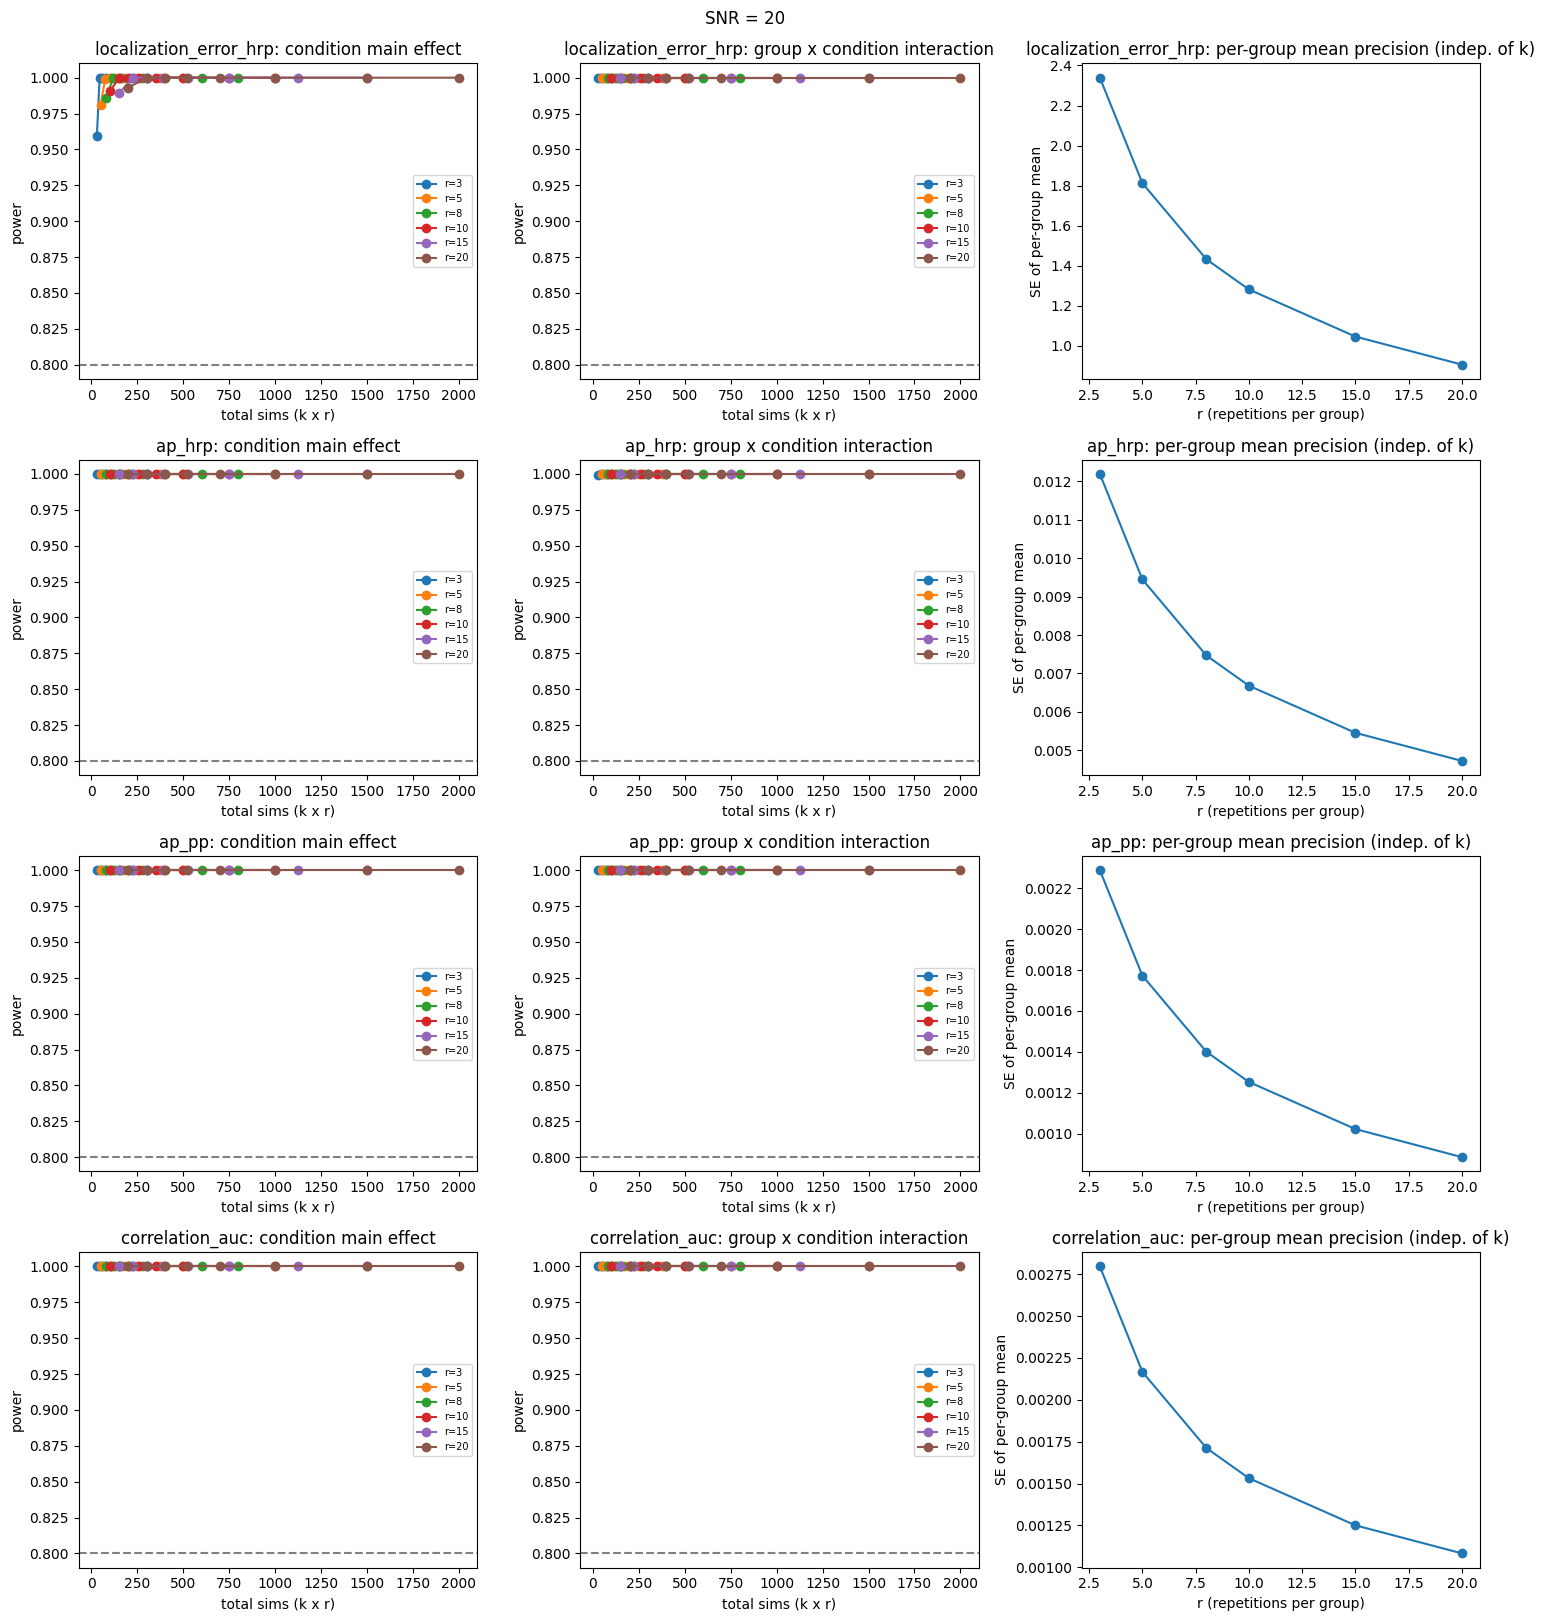

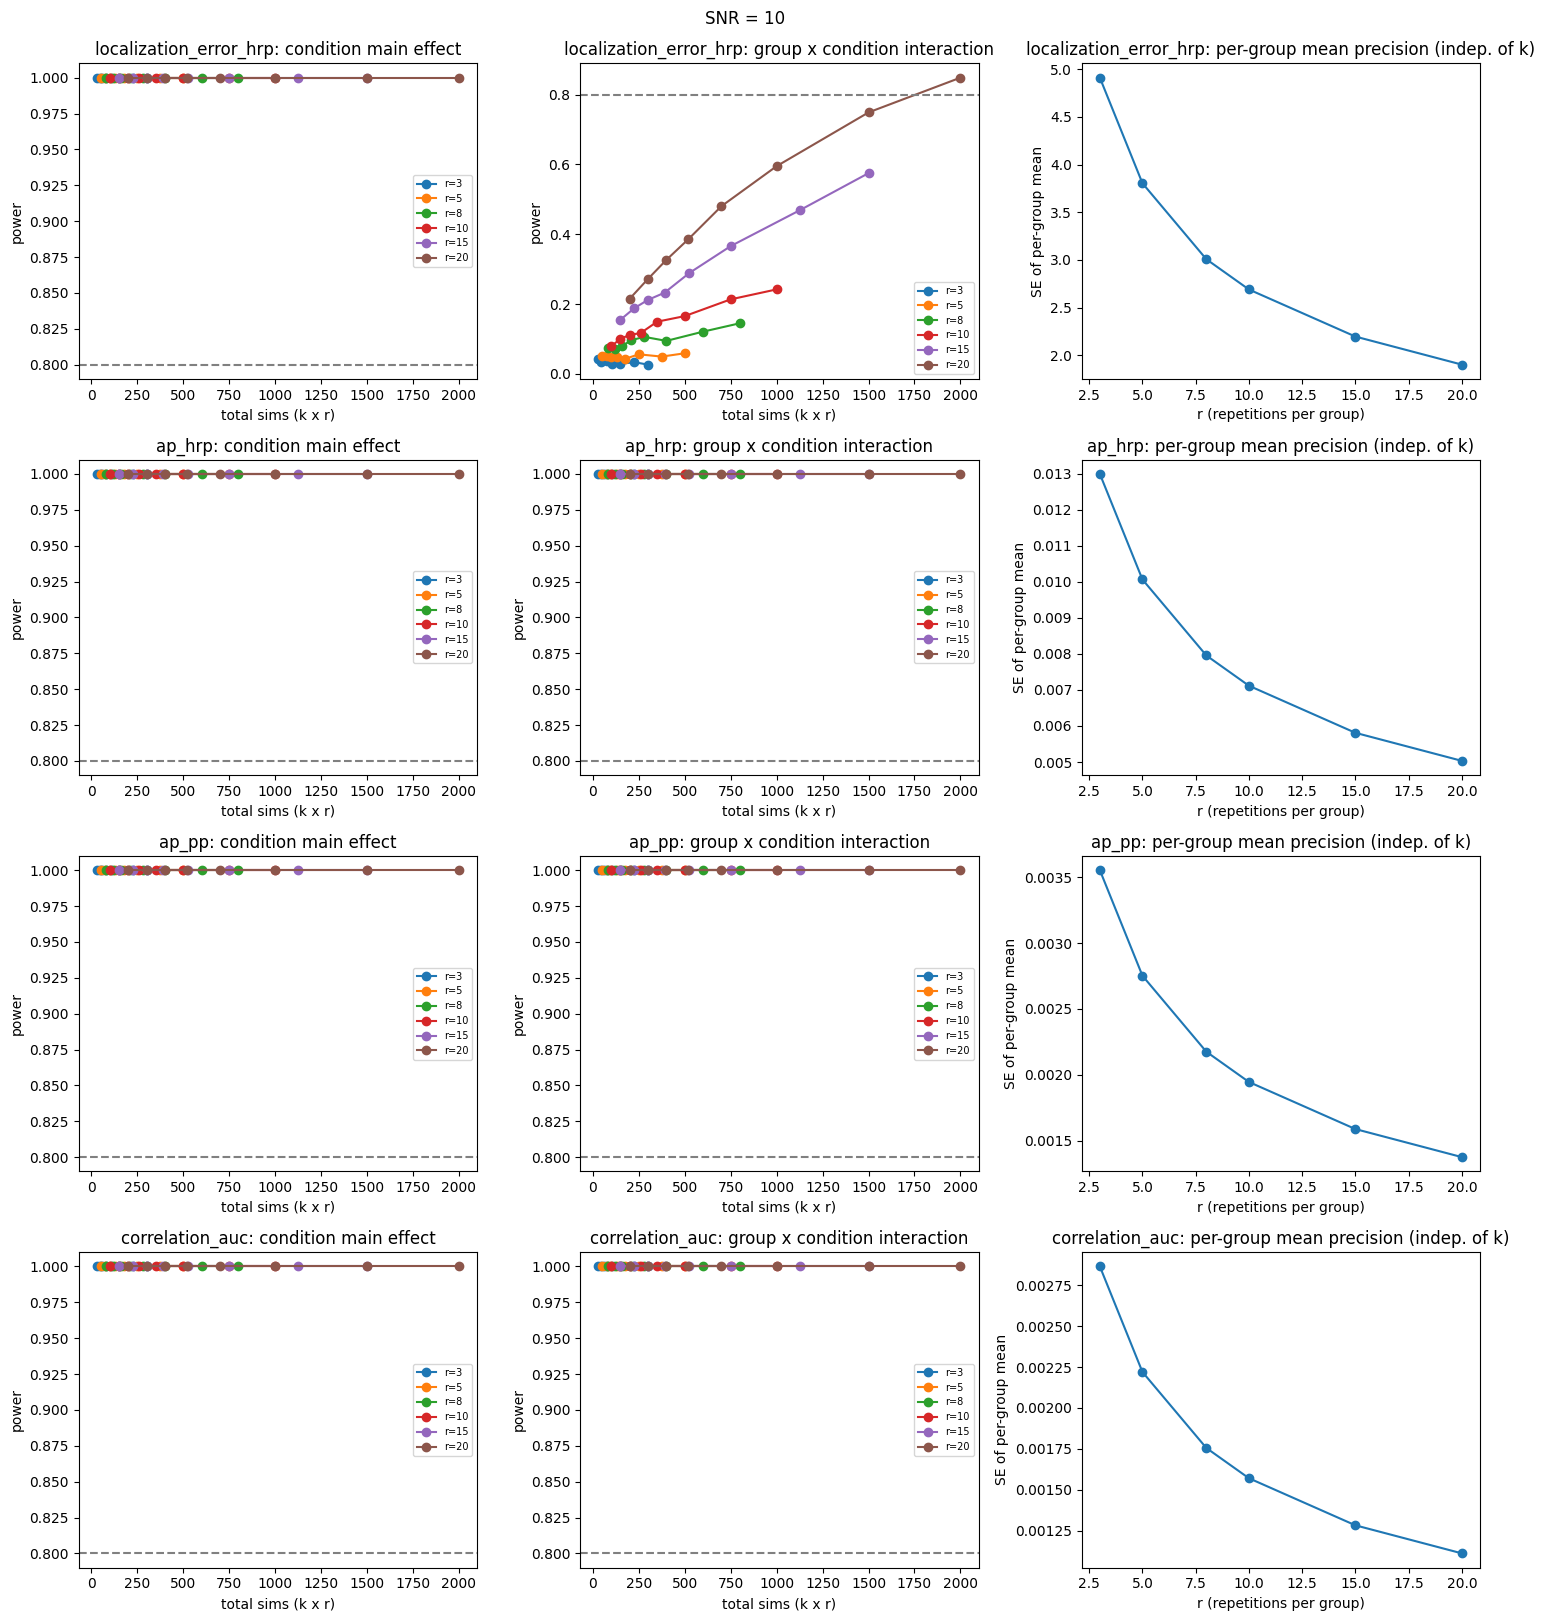

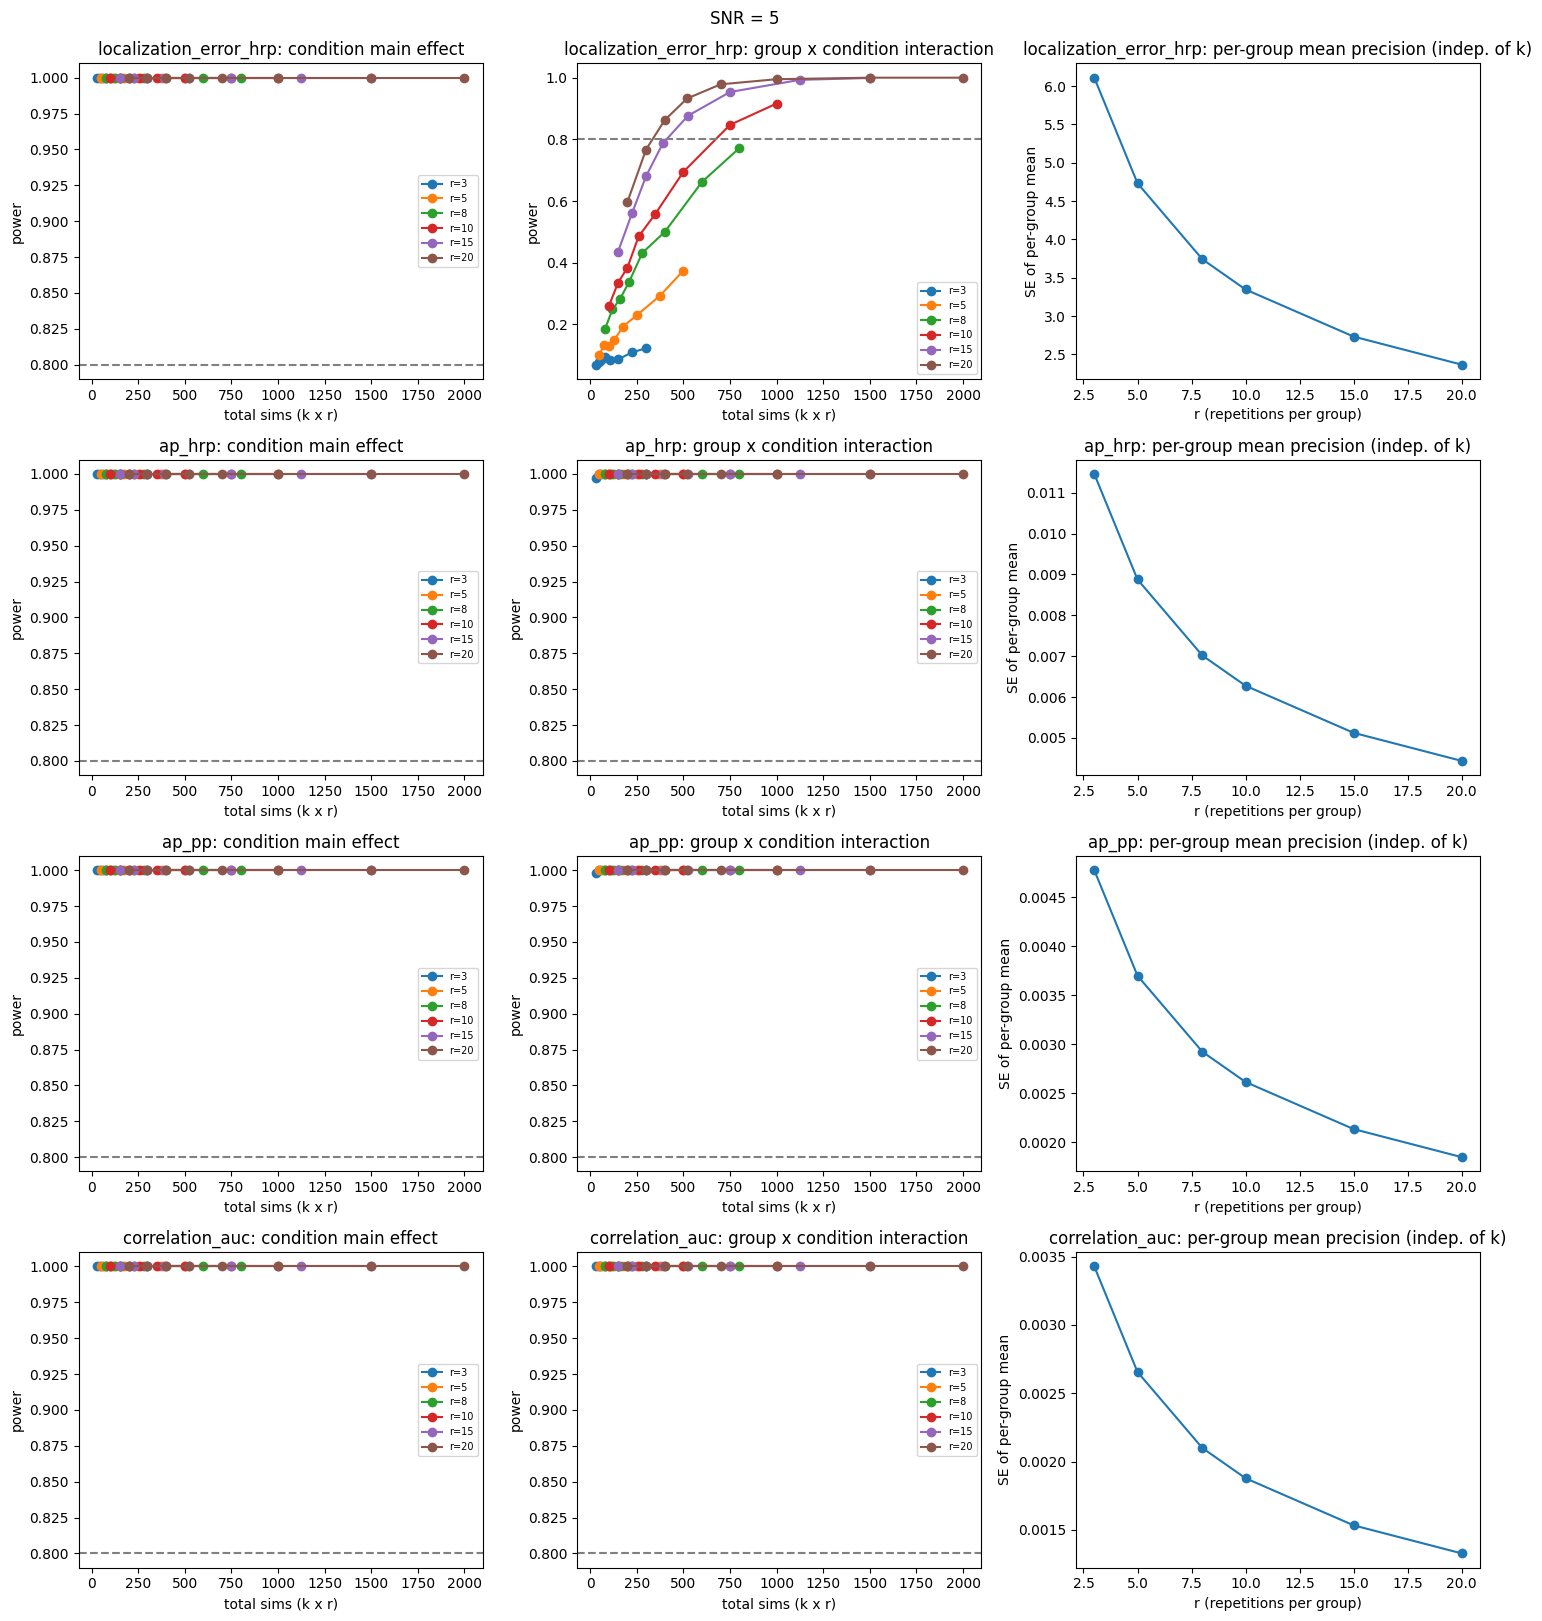

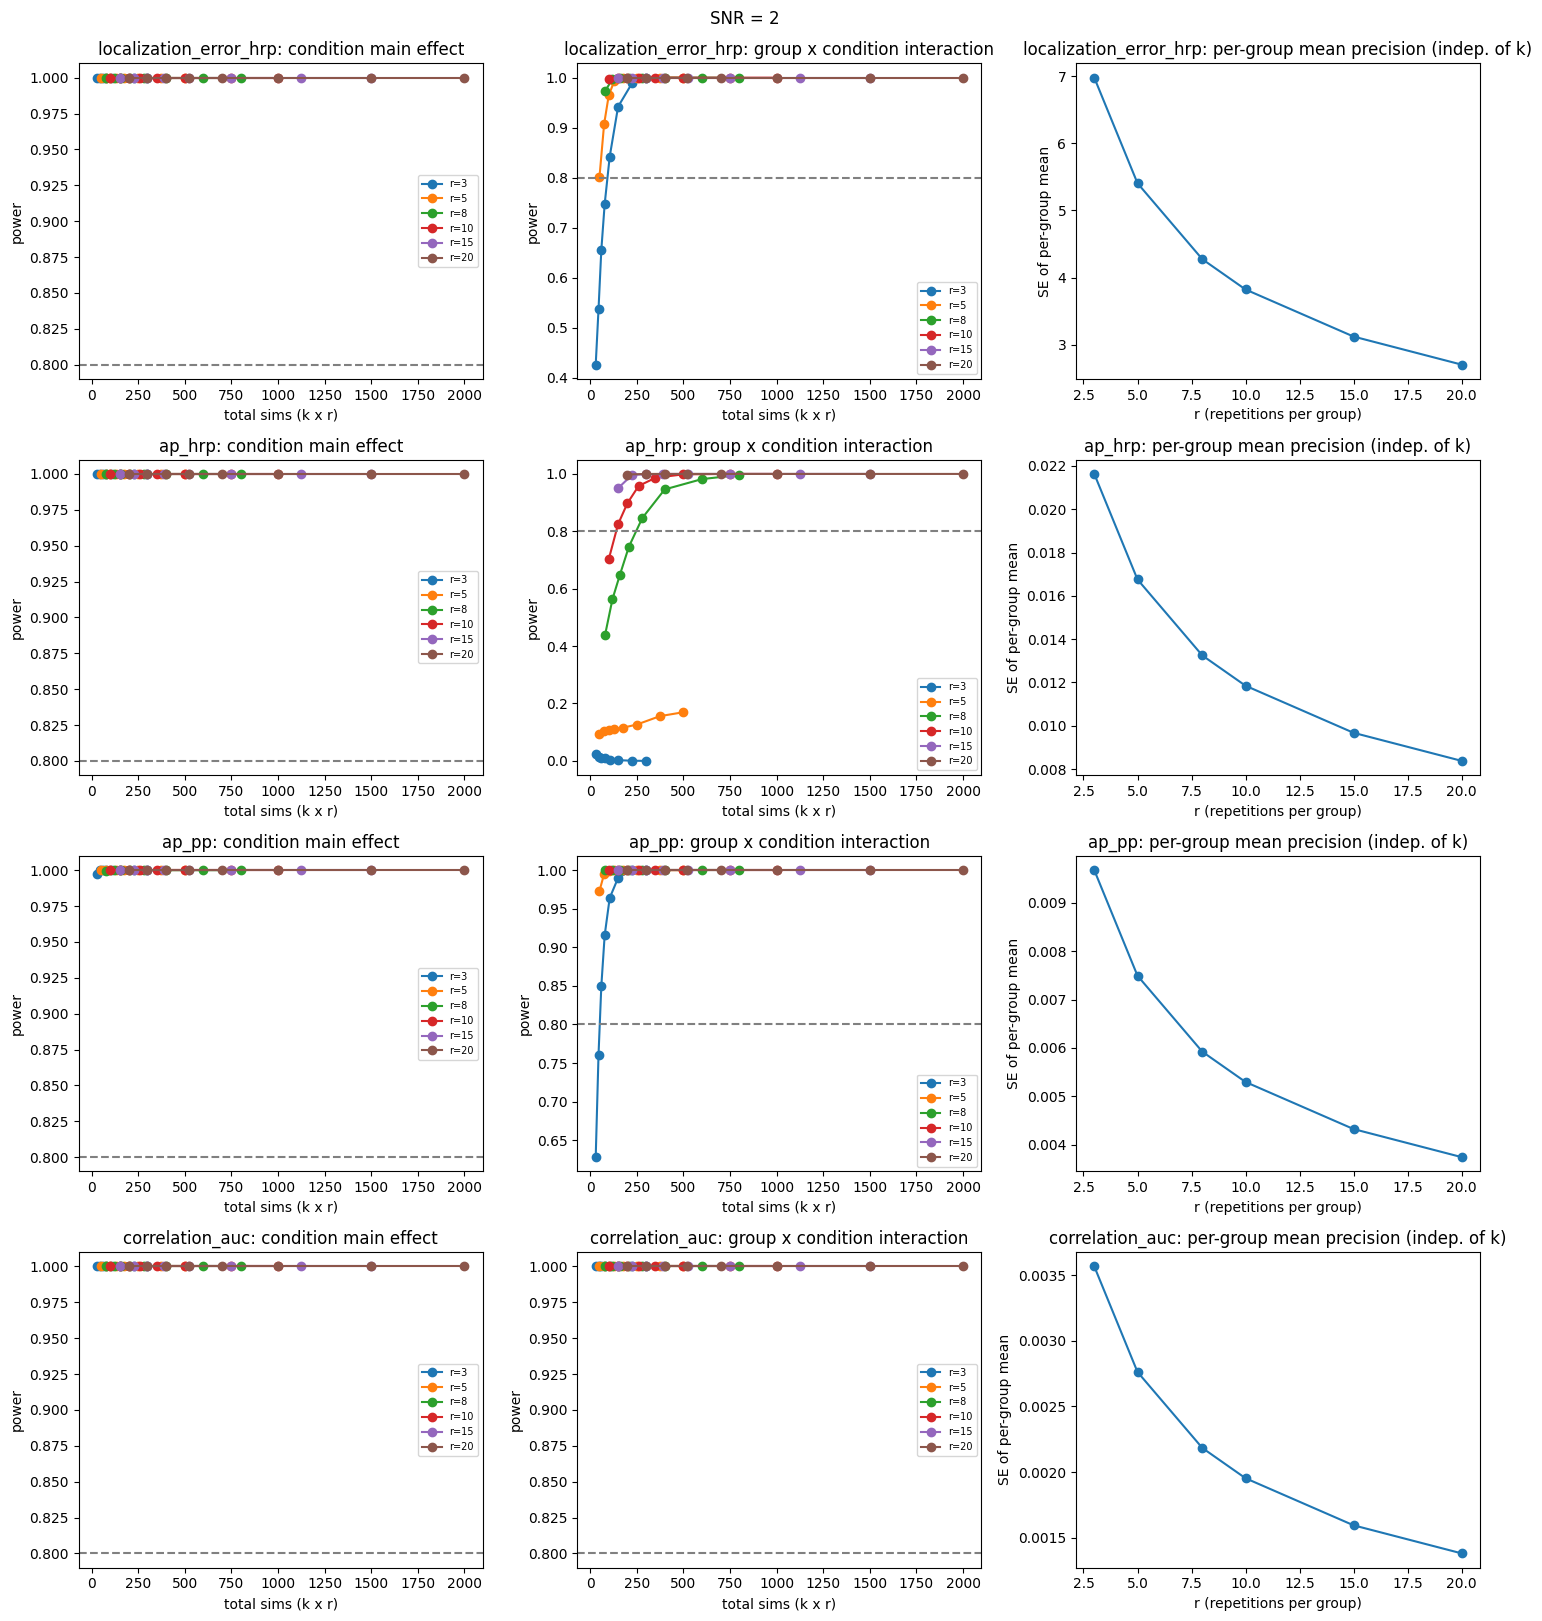

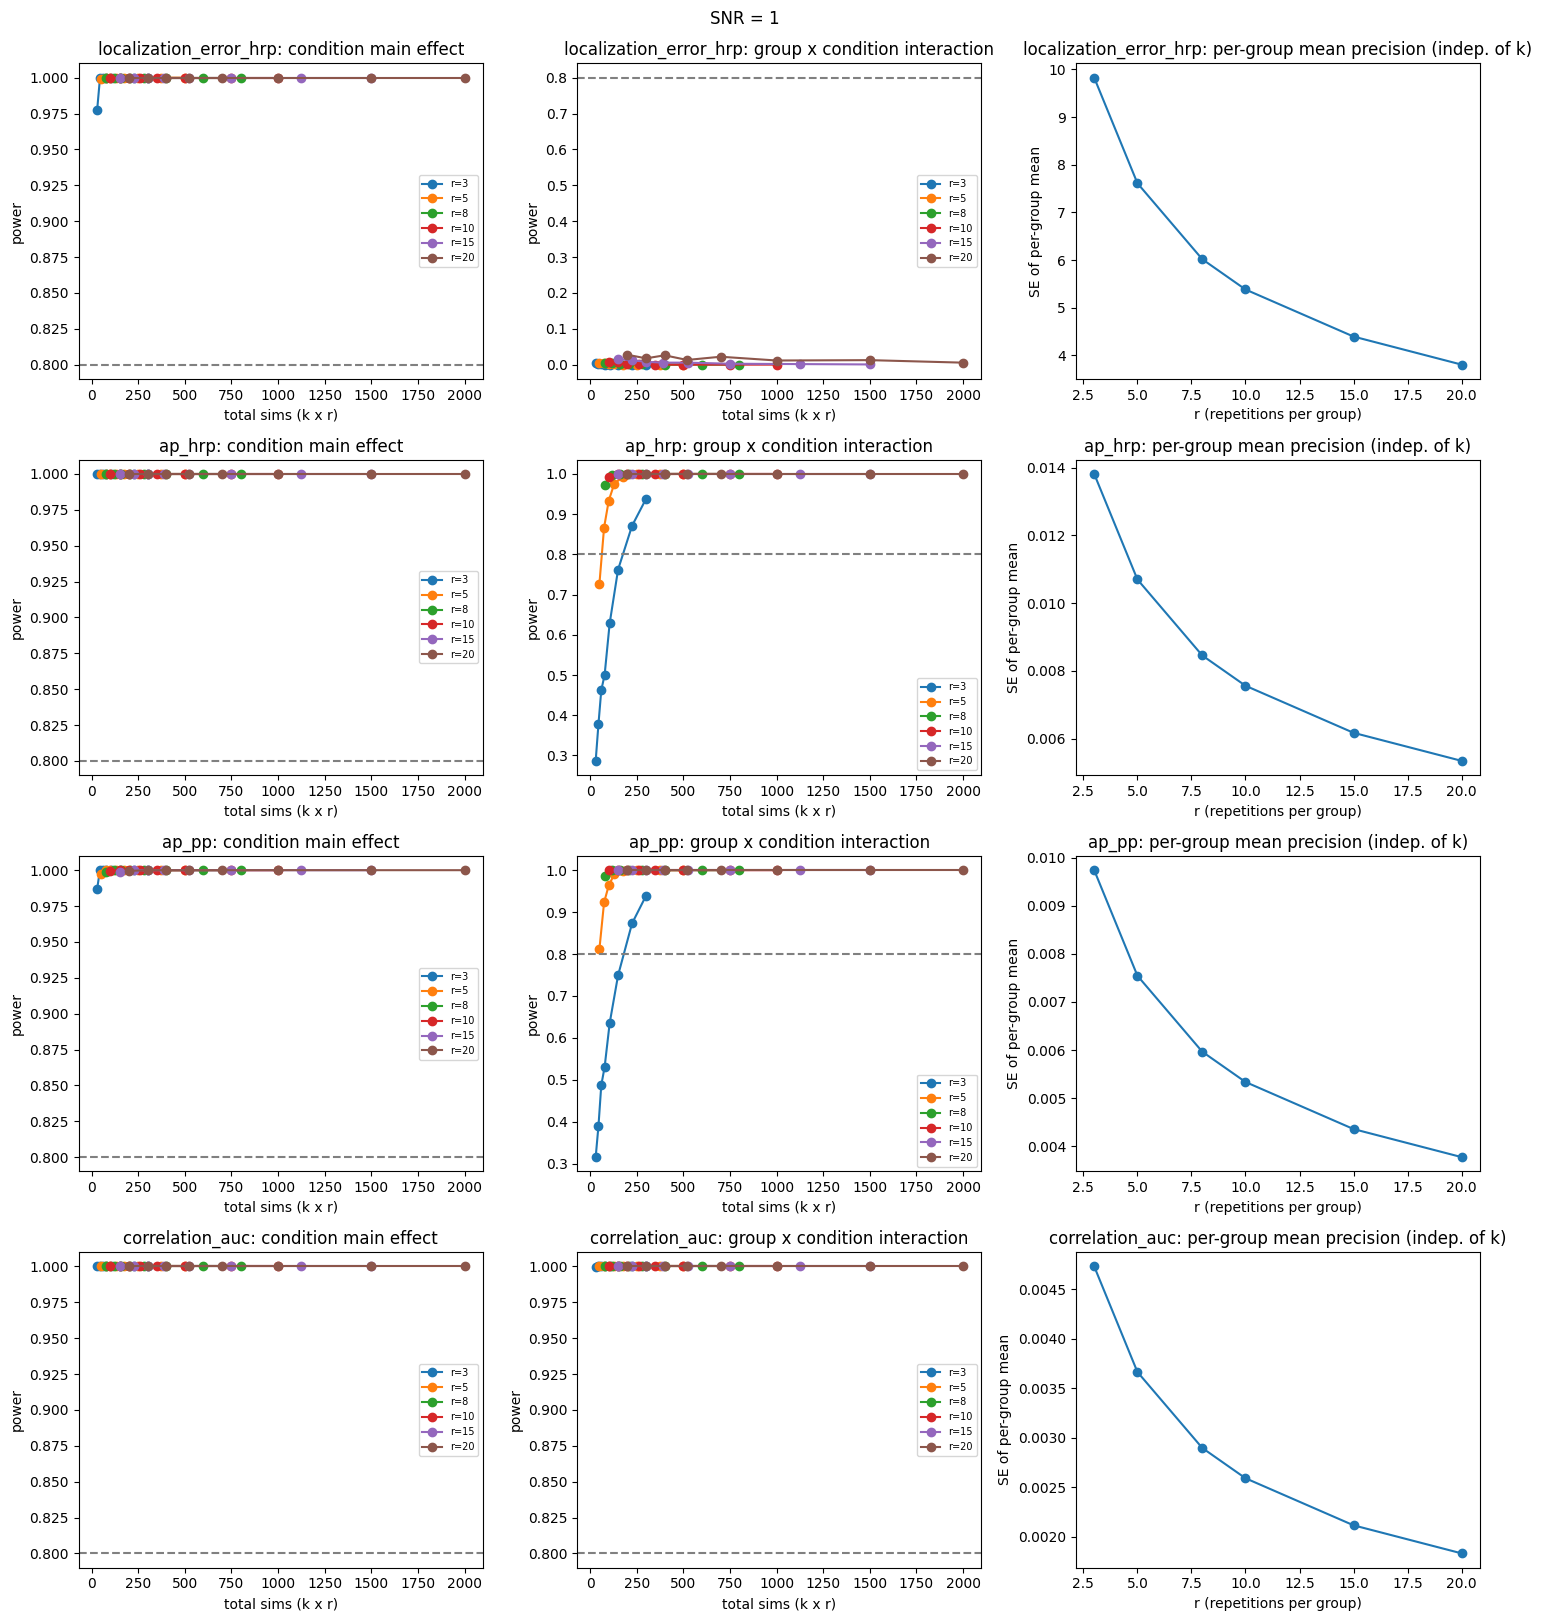

In [5]:
for snr in SNR_LEVELS:
    fig = mm.viz.plot_power_precision_curves(power_results[snr], precision_results[snr], k_grid, r_grid, OUTCOMES)
    fig.suptitle(f"SNR = {snr}", y=1.01)
    fig.savefig(f"pilot_noise_power_curves_snr{snr}.png", dpi=130)

## ✅ - Recommendation

Sized to the worst `(outcome, snr, test)` combination across the whole grid -- same
"size to the hardest case" principle as the original pilot, just extended across noise
levels. Interaction-test power (`method x region`) is checked separately from the
condition/main-effect test, since the original pilot found the main effect saturated
near 1.0 everywhere and the interaction test was the actual binding constraint -- worth
re-verifying rather than assuming here, since a noisier condition could plausibly widen
real method differences instead (i.e. the main effect might *not* saturate at low SNR).

In [6]:
def worst_case_power(power_results, test):
    worst = np.ones((len(k_grid), len(r_grid)))
    for snr in SNR_LEVELS:
        for outcome in OUTCOMES:
            worst = np.minimum(worst, power_results[snr][outcome][test])
    return worst

worst_condition = worst_case_power(power_results, "condition")
worst_interaction = worst_case_power(power_results, "interaction")

THRESHOLD = 0.8
for name, worst in [("condition (main effect)", worst_condition), ("interaction (method x region)", worst_interaction)]:
    ok = worst >= THRESHOLD
    if not ok.any():
        print(f"{name}: no (k, r) in this grid reaches {THRESHOLD} power across every outcome/snr -- extend the grid.")
        continue
    # smallest total sims (k*r) among grid points clearing the threshold
    total_sims = np.array(k_grid)[:, None] * np.array(r_grid)[None, :]
    candidates = np.where(ok, total_sims, np.inf)
    i, j = np.unravel_index(np.argmin(candidates), candidates.shape)
    print(f"{name}: smallest design clearing {THRESHOLD} power everywhere -- "
          f"k={k_grid[i]} regions, r={r_grid[j]} repetitions "
          f"(worst-case power={worst[i, j]:.3f}, total sims/method={k_grid[i]*r_grid[j]}).")

condition (main effect): smallest design clearing 0.8 power everywhere -- k=10 regions, r=3 repetitions (worst-case power=0.960, total sims/method=30).
interaction (method x region): no (k, r) in this grid reaches 0.8 power across every outcome/snr -- extend the grid.
